In [1]:
import pandas as pd
import numpy as np


In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
df.lead_source = df.lead_source.fillna('NA')
df.industry = df.industry.fillna('NA')
df.employment_status = df.employment_status.fillna('NA')
df.location = df.location.fillna('NA')

df.annual_income = df.annual_income.fillna(0.0)
df.lead_score = df.lead_score.fillna(0.0)

In [5]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

### Question 1: ROC AUC feature importance (lead_score)

In [6]:
from sklearn.metrics import roc_auc_score

y = df_train.converted.values

lead_score = df_train.lead_score.values
number_of_courses_viewed = df_train.number_of_courses_viewed.values
interaction_count = df_train.interaction_count.values
annual_income = df_train.annual_income.values

print(roc_auc_score(y, lead_score))
print(roc_auc_score(y, number_of_courses_viewed))
print(roc_auc_score(y, interaction_count))
print(roc_auc_score(y, annual_income))

0.7882254810906102
0.7229894623989618
0.7649203047563227
0.6081977776250831


### Question 2: Training the model (0.732)

In [7]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income","number_of_courses_viewed","interaction_count", "lead_score"]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [8]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

print(roc_auc_score(y_val, y_pred))

0.7318222288173319


### Question 3: Precision and Recall (0.63)

Threshold with min difference between precision and recall: 0.63


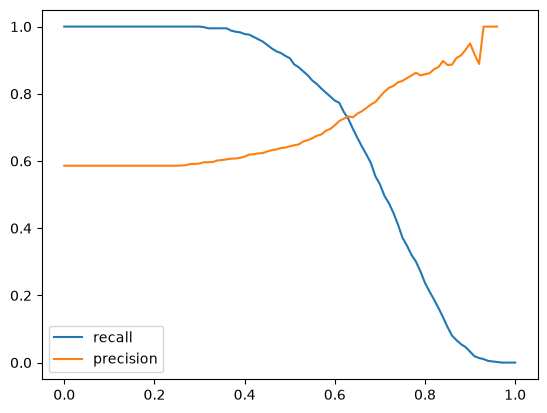

In [10]:
import matplotlib.pyplot as plt

scores = []

thresholds = np.linspace(0, 1, 101)

min_diff = float('inf')
min_t = 0

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    if tp+fn!=0 and tp+fp!=0:
        recall = tp/(tp+fn)
        precision = tp/(tp+fp)
        if abs(recall - precision) < min_diff:
            min_diff = abs(recall - precision)
            min_t=t
    
    scores.append((t, tp, fp, fn, tn))

print(f"Threshold with min difference between precision and recall: {min_t}")

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)

plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
plt.legend()

### Question 4: F1 score (0.41)

    threshold   tp   fp  fn  tn    recall  precision        f1
41       0.41  572  352  14  62  0.976109   0.619048  0.757616


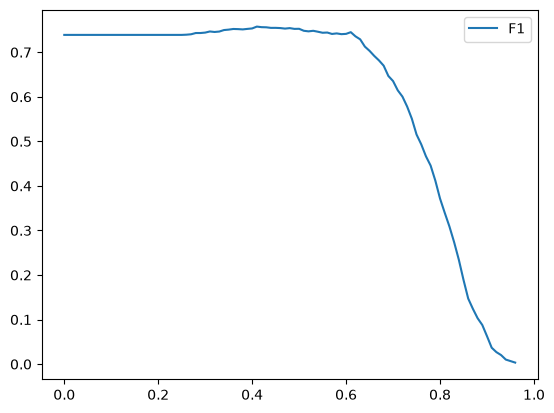

In [16]:
df_scores['f1'] = 2*df_scores.recall*df_scores.precision / (df_scores.recall + df_scores.precision)

print(df_scores[df_scores['f1'] == df_scores['f1'].max()])
plt.plot(df_scores.threshold, df_scores['f1'], label='F1')
plt.legend()


### Question 5: 5-Fold CV (0.007)

In [22]:
from sklearn.model_selection import KFold

def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
    
print(f'{np.mean(scores):.3f} {np.std(scores):.3f}')


0.732 0.007


### Question 6: Hyperparameter Tuning (0.001)

In [23]:

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
        
    print(f'{C} {np.mean(scores):.3f} {np.std(scores):.3f}')

1e-06 0.617 0.019
0.001 0.749 0.010
1 0.732 0.007
